# Simulated Annealing

In [1]:
import math
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
def f(x):
    return x**2 + 10 * np.sin(x)

In [3]:
def simulated_annealing(x0, T0, alpha, T_min, step=1.0, seed=42, lo=-10, hi=10):
    rng = random.Random(seed)
    x, fx = x0, f(x0)
    best_x, best_f = x, fx
    T = T0
    path = [(x, fx)]
    best_history = [best_f]
    while T >= T_min:
        candidate = min(max(x + rng.uniform(-step, step), lo), hi)
        delta = f(candidate) - fx
        if delta <= 0 or rng.random() < math.exp(-delta / T):
            x, fx = candidate, f(candidate)
            if fx < best_f:
                best_x, best_f = x, fx
        path.append((x, fx))
        best_history.append(best_f)
        T *= alpha
    return best_x, best_f, path, best_history

In [4]:
x0 = 8
T0 = 100
alpha = 0.95
T_min = 0.001
neighbour_step = 2.0

In [5]:
best_x, best_f, path, best_history = simulated_annealing(x0, T0, alpha, T_min, neighbour_step)

print(f"Iterations     : {len(path) - 1}")
print(f"Best x         : {best_x:.4f}")
print(f"Minimum f(x)   : {best_f:.4f}")

Iterations     : 225
Best x         : -1.3055
Minimum f(x)   : -7.9458


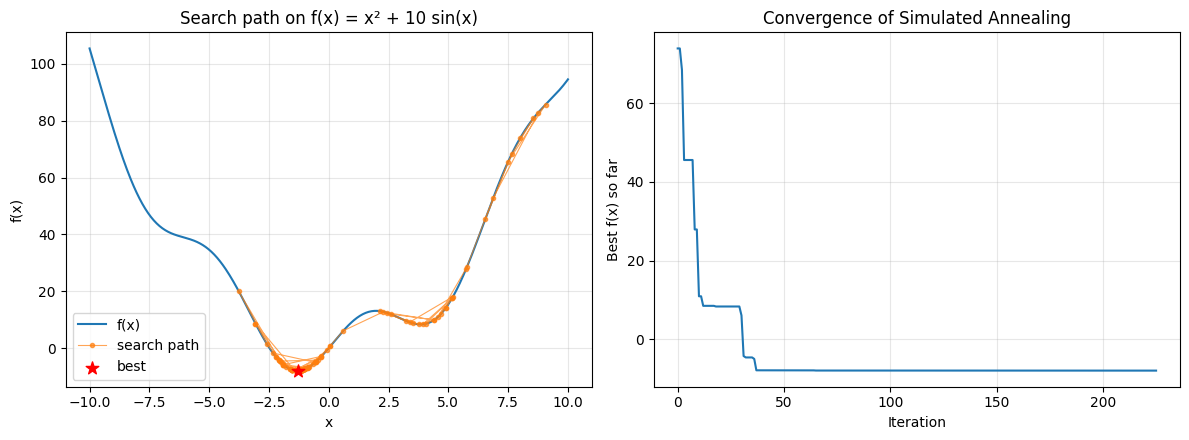

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

xs = np.linspace(-10, 10, 500)
px, py = zip(*path)
ax[0].plot(xs, f(xs), label="f(x)")
ax[0].plot(px, py, "o-", ms=3, lw=0.8, alpha=0.7, label="search path")
ax[0].scatter(best_x, best_f, c="red", s=90, marker="*", zorder=5, label="best")
ax[0].set_xlabel("x")
ax[0].set_ylabel("f(x)")
ax[0].set_title("Search path on f(x) = x² + 10 sin(x)")
ax[0].legend()

ax[1].plot(best_history)
ax[1].set_xlabel("Iteration")
ax[1].set_ylabel("Best f(x) so far")
ax[1].set_title("Convergence of Simulated Annealing")

for a in ax:
    a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
settings = [
    ("Initial Temperature T0", "100", "20", dict(T0=20)),
    ("Cooling Rate alpha", "0.95", "0.80", dict(alpha=0.80)),
    ("Stopping Temperature T_min", "0.001", "0.5", dict(T_min=0.5)),
    ("Initial Solution x0", "8", "-8", dict(x0=-8)),
]
base = dict(x0=x0, T0=T0, alpha=alpha, T_min=T_min)
rows = []
for name, old, new, change in settings:
    res = simulated_annealing(step=neighbour_step, **{**base, **change})
    rows.append([name, old, new, f"x = {best_x:.4f}, f = {best_f:.4f}", f"x = {res[0]:.4f}, f = {res[1]:.4f}", f"{len(res[2]) - 1} iterations"])
table = pd.DataFrame(rows, columns=["Parameter", "Original", "Modified", "Original Result", "Modified Result", "Iterations (modified)"])
table

,Parameter,Original,Modified,Original Result,Modified Result,Iterations (modified)
0,Initial Temperature T0,100,20,"x = -1.3055, f = -7.9458","x = -1.3114, f = -7.9457",194 iterations
1,Cooling Rate alpha,0.95,0.80,"x = -1.3055, f = -7.9458","x = 3.8589, f = 8.3175",52 iterations
2,Stopping Temperature T_min,0.001,0.5,"x = -1.3055, f = -7.9458","x = -1.3642, f = -7.9263",104 iterations
3,Initial Solution x0,8,-8,"x = -1.3055, f = -7.9458","x = -1.3731, f = -7.9198",225 iterations
